In [2]:
import pandas as pd
import numpy as np
import os
import zipfile
print("Python is working!")

Python is working!


In [4]:
import os
print(os.listdir('/content'))

['.config', '20440518-QuickCart_Stockout_Risk_Project_Spec.zip', 'sample_data']


In [5]:
import zipfile
import os
zip_path = "/content/20440518-QuickCart_Stockout_Risk_Project_Spec.zip"
extract_path = "/content/QuickCart_Project"
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)
print("Project extracted successfully!")
print(os.listdir(extract_path))

Project extracted successfully!
['QuickCart_Stockout_Risk_Project_Spec.pdf', 'dim_events.zip']


In [6]:
import os
for root, folders, files in os.walk("/content/QuickCart_Project"):
    for file in files:
        print(os.path.join(root, file))

/content/QuickCart_Project/QuickCart_Stockout_Risk_Project_Spec.pdf
/content/QuickCart_Project/dim_events.zip


In [7]:
import zipfile
import os
events_zip = "/content/QuickCart_Project/dim_events.zip"
events_path = "/content/QuickCart_Project/data"
with zipfile.ZipFile(events_zip, 'r') as zip_ref:
    zip_ref.extractall(events_path)
print("Data extracted successfully!")
for root, folders, files in os.walk(events_path):
    for file in files:
        print(os.path.join(root, file))

Data extracted successfully!
/content/QuickCart_Project/data/dim_suppliers.csv
/content/QuickCart_Project/data/dim_skus.csv
/content/QuickCart_Project/data/dim_events.csv
/content/QuickCart_Project/data/dim_stores.csv
/content/QuickCart_Project/data/fact_inventory_daily.csv


In [8]:
import pandas as pd
data_path = "/content/QuickCart_Project/data"
suppliers = pd.read_csv(data_path + "/dim_suppliers.csv")
skus = pd.read_csv(data_path + "/dim_skus.csv")
events = pd.read_csv(data_path + "/dim_events.csv")
stores = pd.read_csv(data_path + "/dim_stores.csv")
inventory = pd.read_csv(data_path + "/fact_inventory_daily.csv")
print("All files loaded successfully!")

All files loaded successfully!


In [9]:
print("Suppliers:", suppliers.shape)
print("SKUs:", skus.shape)
print("Events:", events.shape)
print("Stores:", stores.shape)
print("Inventory:", inventory.shape)

Suppliers: (15, 6)
SKUs: (60, 9)
Events: (30, 5)
Stores: (12, 8)
Inventory: (21600, 16)


In [10]:
print("===== SUPPLIERS =====")
print(suppliers.columns.tolist())
print("\n===== SKUs =====")
print(skus.columns.tolist())
print("\n===== EVENTS =====")
print(events.columns.tolist())
print("\n===== STORES =====")
print(stores.columns.tolist())
print("\n===== INVENTORY =====")
print(inventory.columns.tolist())

===== SUPPLIERS =====
['supplier_id', 'supplier_name', 'categories_supplied', 'reliability_score', 'base_lead_time_days', 'lead_time_variance_days']

===== SKUs =====
['sku_id', 'sku_name', 'category', 'unit_price_inr', 'shelf_life_days', 'is_perishable', 'festive_relevant', 'popularity_tier', 'supplier_id']

===== EVENTS =====
['date', 'event_name', 'event_type', 'demand_multiplier_festive', 'demand_multiplier_other']

===== STORES =====
['store_id', 'city', 'city_display', 'city_tier', 'store_size', 'sqft', 'opened_year', 'baseline_daily_orders']

===== INVENTORY =====
['date', 'store_id', 'sku_id', 'supplier_id', 'opening_stock', 'units_demanded', 'units_sold', 'closing_stock', 'reorder_point', 'reorder_placed', 'lead_time_days_expected', 'lead_time_days_actual', 'sales_velocity_7d', 'days_of_cover', 'is_festival_week', 'stockout_risk']


In [11]:
for i, col in enumerate(inventory.columns, 1):
    print(i, ":", col)

1 : date
2 : store_id
3 : sku_id
4 : supplier_id
5 : opening_stock
6 : units_demanded
7 : units_sold
8 : closing_stock
9 : reorder_point
10 : reorder_placed
11 : lead_time_days_expected
12 : lead_time_days_actual
13 : sales_velocity_7d
14 : days_of_cover
15 : is_festival_week
16 : stockout_risk


In [12]:
print("Missing values in each column:")
print(inventory.isnull().sum())

Missing values in each column:
date                           0
store_id                       0
sku_id                         0
supplier_id                    0
opening_stock                  0
units_demanded                 0
units_sold                     0
closing_stock                  0
reorder_point                  0
reorder_placed                 0
lead_time_days_expected        0
lead_time_days_actual      19899
sales_velocity_7d              0
days_of_cover                  0
is_festival_week               0
stockout_risk                  0
dtype: int64


In [13]:
print("\nMissing values in suppliers:")
print(suppliers.isnull().sum())
print("\nMissing values in SKUs:")
print(skus.isnull().sum())
print("\nMissing values in stores:")
print(stores.isnull().sum())
print("\nMissing values in events:")
print(events.isnull().sum())


Missing values in suppliers:
supplier_id                0
supplier_name              0
categories_supplied        0
reliability_score          3
base_lead_time_days        0
lead_time_variance_days    0
dtype: int64

Missing values in SKUs:
sku_id              0
sku_name            0
category            0
unit_price_inr      0
shelf_life_days     0
is_perishable       0
festive_relevant    0
popularity_tier     0
supplier_id         0
dtype: int64

Missing values in stores:
store_id                 0
city                     0
city_display             0
city_tier                0
store_size               0
sqft                     0
opened_year              0
baseline_daily_orders    0
dtype: int64

Missing values in events:
date                         0
event_name                   0
event_type                   0
demand_multiplier_festive    0
demand_multiplier_other      0
dtype: int64


In [14]:
print("Stockout Risk distribution:")
print(inventory["stockout_risk"].value_counts())
print("\nPercentage distribution:")
print(
    inventory["stockout_risk"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Stockout Risk distribution:
stockout_risk
Safe        14131
At-Risk      5186
Imminent     2283
Name: count, dtype: int64

Percentage distribution:
stockout_risk
Safe        65.42
At-Risk     24.01
Imminent    10.57
Name: proportion, dtype: float64


In [15]:
# Make copies so the original datasets stay unchanged
df = inventory.copy()
# Convert dates to datetime
df["date"] = pd.to_datetime(df["date"])
events["date"] = pd.to_datetime(events["date"])
# 1. Add SKU information
df = df.merge(
    skus,
    on="sku_id",
    how="left",
    suffixes=("", "_sku")
)
# 2. Add supplier information
df = df.merge(
    suppliers,
    on="supplier_id",
    how="left",
    suffixes=("", "_supplier")
)
# 3. Add store information
df = df.merge(
    stores,
    on="store_id",
    how="left",
    suffixes=("", "_store")
)
# 4. Add event information using date
df = df.merge(
    events,
    on="date",
    how="left"
)
print("Merged dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Merged dataset shape: (21600, 40)

Columns:
['date', 'store_id', 'sku_id', 'supplier_id', 'opening_stock', 'units_demanded', 'units_sold', 'closing_stock', 'reorder_point', 'reorder_placed', 'lead_time_days_expected', 'lead_time_days_actual', 'sales_velocity_7d', 'days_of_cover', 'is_festival_week', 'stockout_risk', 'sku_name', 'category', 'unit_price_inr', 'shelf_life_days', 'is_perishable', 'festive_relevant', 'popularity_tier', 'supplier_id_sku', 'supplier_name', 'categories_supplied', 'reliability_score', 'base_lead_time_days', 'lead_time_variance_days', 'city', 'city_display', 'city_tier', 'store_size', 'sqft', 'opened_year', 'baseline_daily_orders', 'event_name', 'event_type', 'demand_multiplier_festive', 'demand_multiplier_other']


In [16]:
# Check missing values in the merged dataset
missing = df.isnull().sum()
print("Columns with missing values:")
print(missing[missing > 0])

Columns with missing values:
lead_time_days_actual    19899
reliability_score         5040
dtype: int64


In [17]:
# Fill missing numerical values with the median
num_cols = df.select_dtypes(include=["int64", "float64"]).columns
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())
# Fill missing categorical values with the mode
cat_cols = df.select_dtypes(include=["object"]).columns
for col in cat_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])
print("Remaining missing values:", df.isnull().sum().sum())

Remaining missing values: 0


In [19]:
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["day"] = df["date"].dt.day
df["day_of_week"] = df["date"].dt.dayofweek
df["week_of_year"] = df["date"].dt.isocalendar().week.astype(int)
df["stock_coverage_days"] = (
    df["stock_on_hand"] / df["avg_daily_demand"].replace(0, 1)
)
# Create demand variability feature
df["demand_variability"] = (
    df["demand_std"] / df["avg_daily_demand"].replace(0, 1)
)
print("Feature engineering completed.")
print("New dataset shape:", df.shape)
print("\nNew features:")
print([
    "year",
    "month",
    "day",
    "day_of_week",
    "week_of_year",
    "stock_coverage_days",
    "demand_variability"
])

KeyError: 'stock_on_hand'

In [20]:
print("All columns in df:")
for i, col in enumerate(df.columns):
    print(i, ":", col)

All columns in df:
0 : date
1 : store_id
2 : sku_id
3 : supplier_id
4 : opening_stock
5 : units_demanded
6 : units_sold
7 : closing_stock
8 : reorder_point
9 : reorder_placed
10 : lead_time_days_expected
11 : lead_time_days_actual
12 : sales_velocity_7d
13 : days_of_cover
14 : is_festival_week
15 : stockout_risk
16 : sku_name
17 : category
18 : unit_price_inr
19 : shelf_life_days
20 : is_perishable
21 : festive_relevant
22 : popularity_tier
23 : supplier_id_sku
24 : supplier_name
25 : categories_supplied
26 : reliability_score
27 : base_lead_time_days
28 : lead_time_variance_days
29 : city
30 : city_display
31 : city_tier
32 : store_size
33 : sqft
34 : opened_year
35 : baseline_daily_orders
36 : event_name
37 : event_type
38 : demand_multiplier_festive
39 : demand_multiplier_other
40 : year
41 : month
42 : day
43 : day_of_week
44 : week_of_year


In [21]:
df["stock_on_hand"] = df["closing_stock"]

In [22]:
# Fix stock_on_hand column
if "stock_on_hand" not in df.columns:
    df["stock_on_hand"] = df["closing_stock"]
print("stock_on_hand created successfully.")
print(df[["opening_stock", "units_sold", "closing_stock", "stock_on_hand"]].head())

stock_on_hand created successfully.
   opening_stock  units_sold  closing_stock  stock_on_hand
0          159.9        15.0          144.9          144.9
1          144.9        10.0          134.9          134.9
2          134.9        15.0          119.9          119.9
3          119.9        10.0          109.9          109.9
4          109.9         9.0          100.9          100.9


In [48]:
print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum().sort_values(ascending=False).head(15))
print("\nDuplicate rows:", df.duplicated().sum())
print("\nStockout risk distribution:")
print(df["stockout_risk"].value_counts(dropna=False))

Dataset shape: (21600, 47)

Missing values:
date                       0
store_id                   0
sku_id                     0
supplier_id                0
opening_stock              0
units_demanded             0
units_sold                 0
closing_stock              0
reorder_point              0
reorder_placed             0
lead_time_days_expected    0
lead_time_days_actual      0
sales_velocity_7d          0
days_of_cover              0
is_festival_week           0
dtype: int64

Duplicate rows: 0

Stockout risk distribution:
stockout_risk
Safe        14131
At-Risk      5186
Imminent     2283
Name: count, dtype: int64


Stockout Risk Distribution:
stockout_risk
Safe        14131
At-Risk      5186
Imminent     2283
Name: count, dtype: int64

Percentage:
stockout_risk
Safe        65.42
At-Risk     24.01
Imminent    10.57
Name: proportion, dtype: float64


,count,mean,std,min,25%,50%,75%,max
opening_stock,21600.0,127.246588,146.969344,0.00,33.375,75.20,162.125,1091.60
units_demanded,21600.0,17.278380,17.560305,0.00,5.750,11.00,23.000,201.00
units_sold,21600.0,16.753565,17.255100,0.00,5.000,11.00,23.000,201.00
closing_stock,21600.0,125.886069,146.120852,0.00,32.800,74.20,160.000,1091.60
reorder_point,21600.0,72.349722,76.896919,3.00,22.750,47.05,90.550,467.40
lead_time_days_expected,21600.0,2.600000,1.496698,1.00,1.000,3.00,4.000,5.00
lead_time_days_actual,21600.0,3.213671,0.486030,1.00,3.200,3.20,3.200,8.20
sales_velocity_7d,21600.0,16.693251,16.009877,0.00,5.570,11.14,23.000,117.57
days_of_cover,21600.0,8.137071,5.153005,0.00,4.310,7.54,11.360,134.85
reliability_score,21600.0,0.748333,0.096182,0.63,0.700,0.71,0.830,0.93


,closing_stock,units_demanded,units_sold,reorder_point,sales_velocity_7d,days_of_cover,lead_time_days_actual,reliability_score
stockout_risk,,,,,,,,
At-Risk,74.32,18.24,18.24,85.12,18.29,4.05,3.11,0.76
Imminent,34.73,18.54,16.50,75.48,17.54,1.95,3.52,0.70
Safe,159.54,16.72,16.25,67.16,15.97,10.64,3.20,0.75


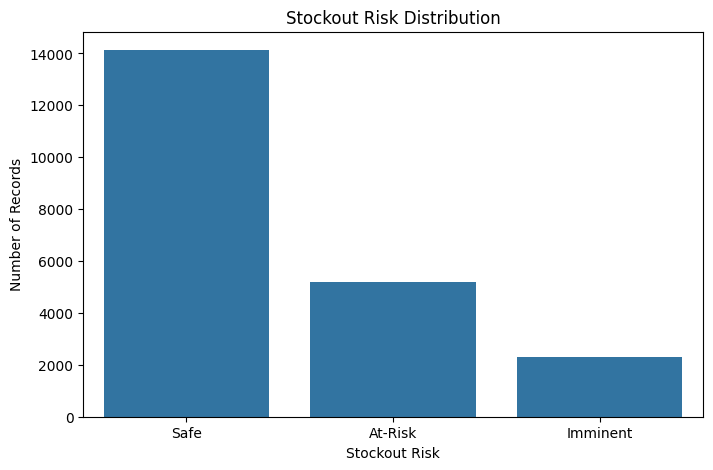

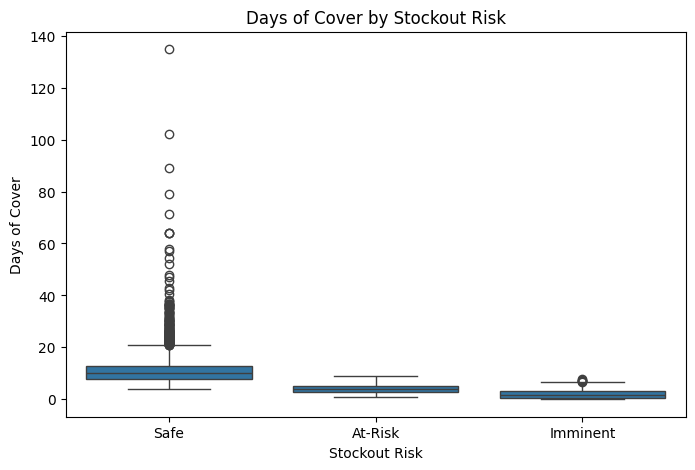

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# 1. Target distribution
print("Stockout Risk Distribution:")
print(df["stockout_risk"].value_counts())
print("\nPercentage:")
print(df["stockout_risk"].value_counts(normalize=True).mul(100).round(2))
# 2. Summary statistics for important numerical variables
numeric_cols = [
    "opening_stock",
    "units_demanded",
    "units_sold",
    "closing_stock",
    "reorder_point",
    "lead_time_days_expected",
    "lead_time_days_actual",
    "sales_velocity_7d",
    "days_of_cover",
    "reliability_score"
]
display(df[numeric_cols].describe().T)
# 3. Average inventory indicators by stockout risk
risk_summary = df.groupby("stockout_risk")[[
    "closing_stock",
    "units_demanded",
    "units_sold",
    "reorder_point",
    "sales_velocity_7d",
    "days_of_cover",
    "lead_time_days_actual",
    "reliability_score"
]].mean().round(2)
display(risk_summary)
# 4. Stockout risk visualization
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x="stockout_risk",
    order=["Safe", "At-Risk", "Imminent"]
)
plt.title("Stockout Risk Distribution")
plt.xlabel("Stockout Risk")
plt.ylabel("Number of Records")
plt.show()
# 5. Days of cover by risk
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x="stockout_risk",
    y="days_of_cover",
    order=["Safe", "At-Risk", "Imminent"]
)
plt.title("Days of Cover by Stockout Risk")
plt.xlabel("Stockout Risk")
plt.ylabel("Days of Cover")
plt.show()

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns
# Numerical variables important for stockout analysis
risk_features = [
    "opening_stock",
    "units_demanded",
    "units_sold",
    "closing_stock",
    "reorder_point",
    "lead_time_days_expected",
    "lead_time_days_actual",
    "sales_velocity_7d",
    "days_of_cover",
    "reliability_score",
    "lead_time_variance_days"
]
# Keep only columns available in the dataset
risk_features = [c for c in risk_features if c in df.columns]
# Average values for each stockout-risk category
risk_summary = (
    df.groupby("stockout_risk")[risk_features]
      .mean()
      .round(2)
)
print("Average values by Stockout Risk:")
display(risk_summary)

Average values by Stockout Risk:


,opening_stock,units_demanded,units_sold,closing_stock,reorder_point,lead_time_days_expected,lead_time_days_actual,sales_velocity_7d,days_of_cover,reliability_score,lead_time_variance_days
stockout_risk,,,,,,,,,,,
At-Risk,92.56,18.24,18.24,74.32,85.12,3.05,3.11,18.29,4.05,0.76,1.32
Imminent,51.22,18.54,16.50,34.73,75.48,3.29,3.52,17.54,1.95,0.70,1.14
Safe,152.26,16.72,16.25,159.54,67.16,2.32,3.20,15.97,10.64,0.75,1.42


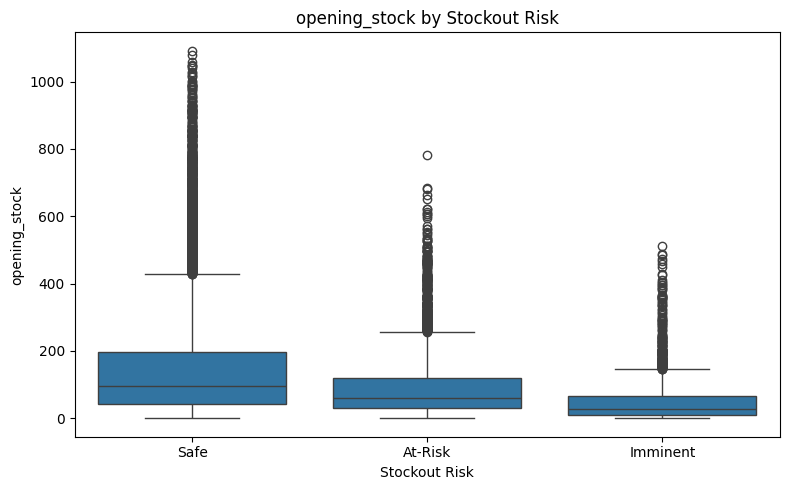

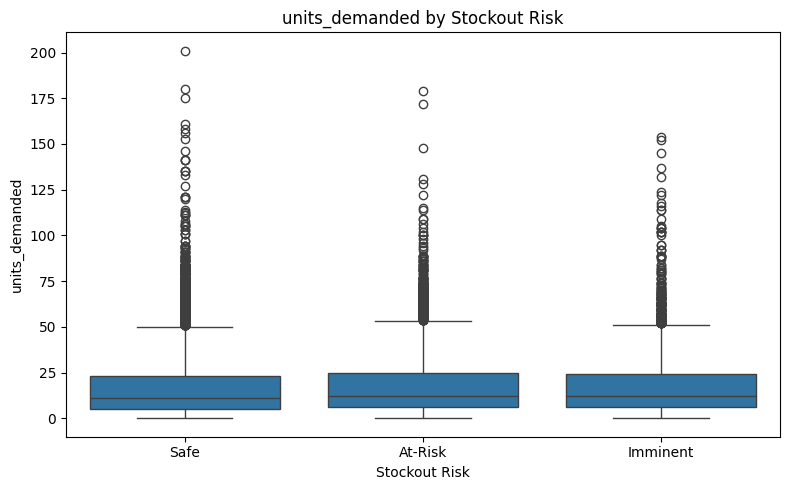

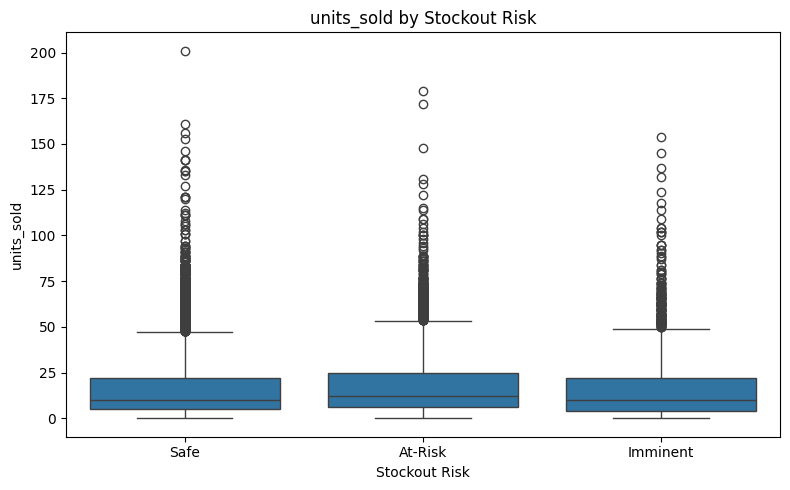

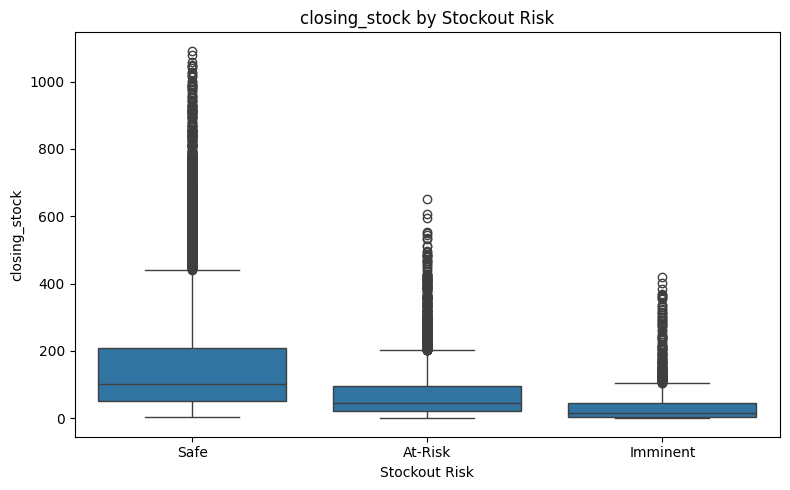

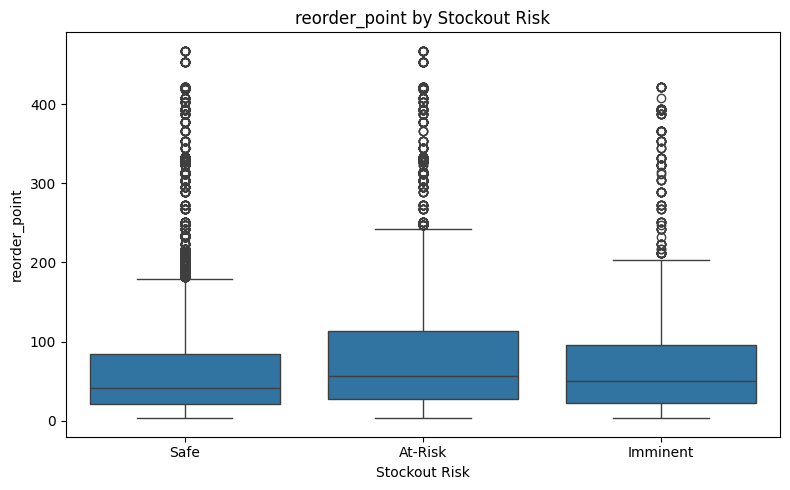

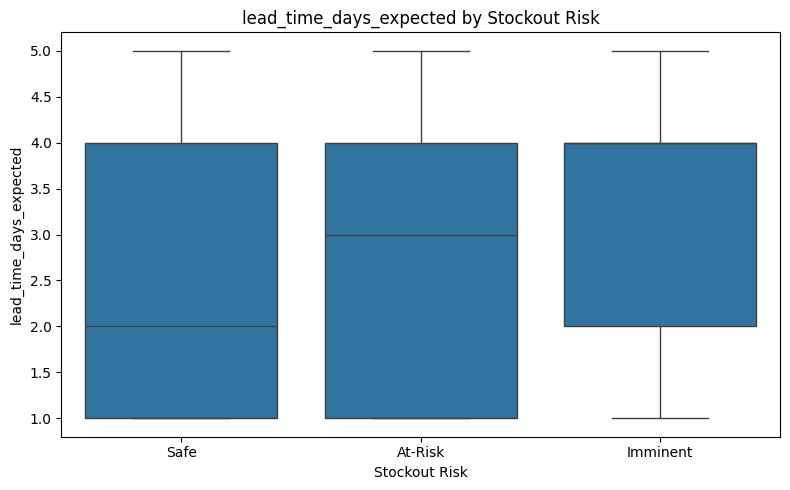

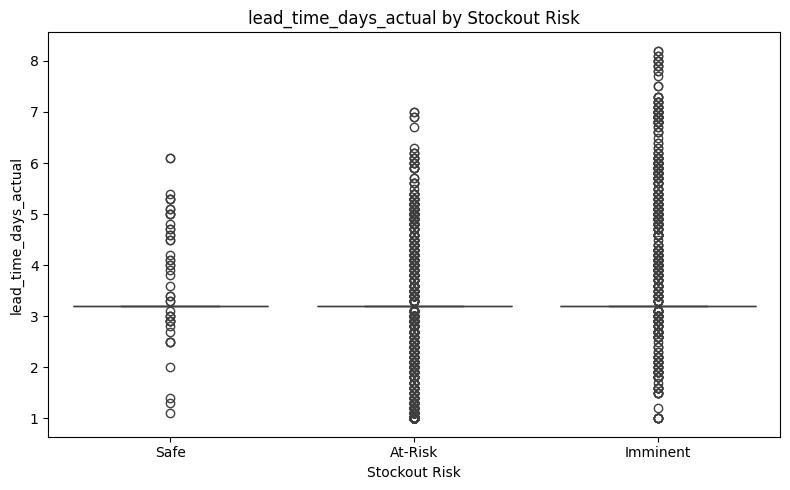

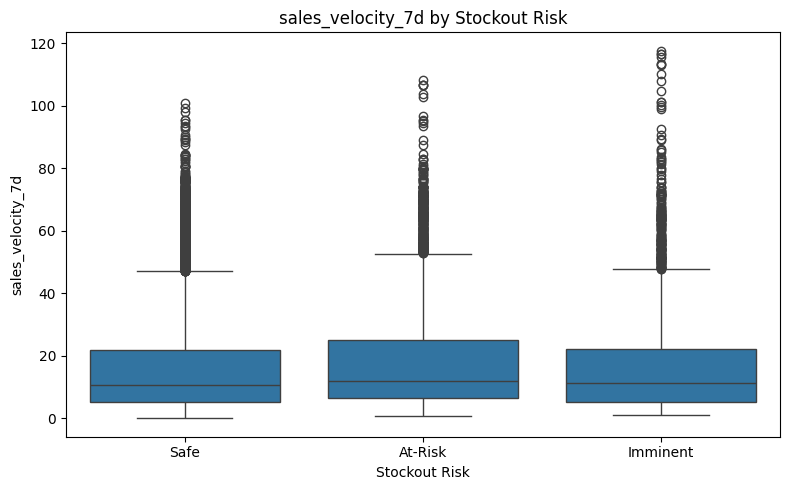

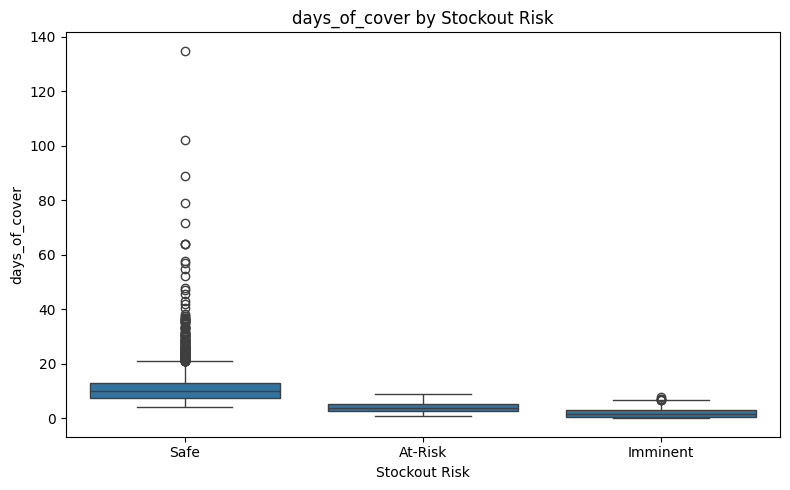

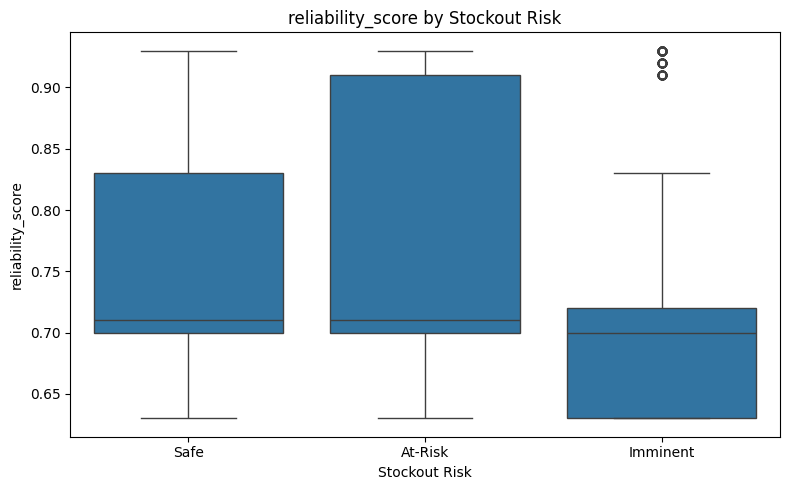

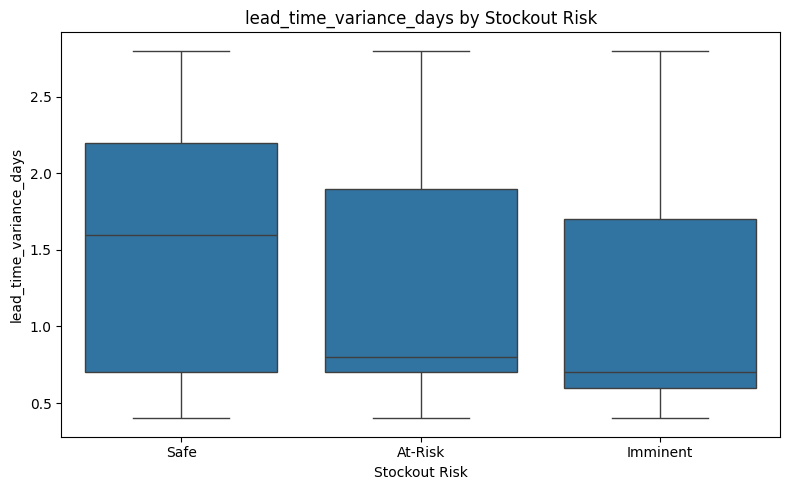

In [26]:
for feature in risk_features:
    plt.figure(figsize=(8, 5))
    sns.boxplot(
        data=df,
        x="stockout_risk",
        y=feature
    )
    plt.title(f"{feature} by Stockout Risk")
    plt.xlabel("Stockout Risk")
    plt.ylabel(feature)
    plt.tight_layout()
    plt.show()

In [33]:
target = "stockout_risk"
# Variables that may directly determine stockout_risk
potential_leakage = [
    "closing_stock",
    "days_of_cover",
    "reorder_point",
    "opening_stock",
    "units_sold",
    "units_demanded"
]
print("Checking potential leakage variables:\n")
for col in potential_leakage:
    if col in df.columns:
        print(f"{col}:")
        print(df.groupby(target)[col].mean().round(2))
        print("-" * 50)
# ------------------------------------------------------------
# Features available BEFORE the stockout outcome
# ------------------------------------------------------------
model_features = [
    "opening_stock",
    "units_demanded",
    "units_sold",
    "reorder_point",
    "lead_time_days_expected",
    "lead_time_days_actual",
    "sales_velocity_7d",
    "days_of_cover",
    "is_festival_week",
    "is_perishable",
    "festive_relevant",
    "popularity_tier",
    "reliability_score",
    "base_lead_time_days",
    "lead_time_variance_days",
    "store_size",
    "sqft",
    "baseline_daily_orders",
    "demand_multiplier_festive",
    "demand_multiplier_other",
    "city_tier"
]
# Keep only columns that exist
model_features = [c for c in model_features if c in df.columns]
print("\nSelected model features:")
for i, col in enumerate(model_features, 1):
    print(i, col)
print("\nNumber of selected features:", len(model_features))

Checking potential leakage variables:

closing_stock:
stockout_risk
At-Risk      74.32
Imminent     34.73
Safe        159.54
Name: closing_stock, dtype: float64
--------------------------------------------------
days_of_cover:
stockout_risk
At-Risk      4.05
Imminent     1.95
Safe        10.64
Name: days_of_cover, dtype: float64
--------------------------------------------------
reorder_point:
stockout_risk
At-Risk     85.12
Imminent    75.48
Safe        67.16
Name: reorder_point, dtype: float64
--------------------------------------------------
opening_stock:
stockout_risk
At-Risk      92.56
Imminent     51.22
Safe        152.26
Name: opening_stock, dtype: float64
--------------------------------------------------
units_sold:
stockout_risk
At-Risk     18.24
Imminent    16.50
Safe        16.25
Name: units_sold, dtype: float64
--------------------------------------------------
units_demanded:
stockout_risk
At-Risk     18.24
Imminent    18.54
Safe        16.72
Name: units_demanded, dtype

In [34]:
# ============================================================
# STEP 7B: Create Modeling Dataset
# ============================================================

X = df[model_features].copy()
y = df[target].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nMissing values in X:")
print(X.isnull().sum().sum())

print("\nModeling dataset is ready.")

X shape: (21600, 21)
y shape: (21600,)

Target distribution:
stockout_risk
Safe        14131
At-Risk      5186
Imminent     2283
Name: count, dtype: int64

Missing values in X:
0

Modeling dataset is ready.


In [35]:
# ============================================================
# STEP 8: Train Stockout Risk Prediction Model
# ============================================================

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

# Split features and target
X = df[model_features].copy()
y = df["stockout_risk"].copy()

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining rows:", len(X_train))
print("Testing rows:", len(X_test))

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Random Forest classifier
rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

# Complete ML pipeline
stockout_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", rf_model)
])

# Train model
stockout_model.fit(X_train, y_train)

print("\n✅ Stockout Risk Model trained successfully!")

Numerical features: 15
Categorical features: 6

Training rows: 17280
Testing rows: 4320

✅ Stockout Risk Model trained successfully!


In [36]:
# ============================================================
# STEP 8B: Generate Predictions
# ============================================================

y_pred = stockout_model.predict(X_test)

print("First 20 predictions:")
print(y_pred[:20])

print("\nActual values:")
print(y_test.iloc[:20].values)

print("\n✅ Predictions generated successfully.")

First 20 predictions:
['Safe' 'Safe' 'Safe' 'Imminent' 'At-Risk' 'Safe' 'At-Risk' 'At-Risk'
 'Safe' 'At-Risk' 'Safe' 'Safe' 'At-Risk' 'Safe' 'Safe' 'Safe' 'Safe'
 'Safe' 'Safe' 'Safe']

Actual values:
['Safe' 'Safe' 'Safe' 'Imminent' 'At-Risk' 'Safe' 'At-Risk' 'At-Risk'
 'Safe' 'At-Risk' 'Safe' 'Safe' 'At-Risk' 'Safe' 'Safe' 'Safe' 'Safe'
 'Safe' 'Safe' 'Safe']

✅ Predictions generated successfully.


MODEL EVALUATION

Accuracy: 0.9609
Accuracy (%): 96.09%

Classification Report:
              precision    recall  f1-score   support

     At-Risk       0.90      0.94      0.92      1037
    Imminent       0.87      0.80      0.83       457
        Safe       1.00      1.00      1.00      2826

    accuracy                           0.96      4320
   macro avg       0.92      0.91      0.92      4320
weighted avg       0.96      0.96      0.96      4320


Confusion Matrix:
[[2814   12    0]
 [  10  973   54]
 [   0   93  364]]


<Figure size 700x500 with 0 Axes>

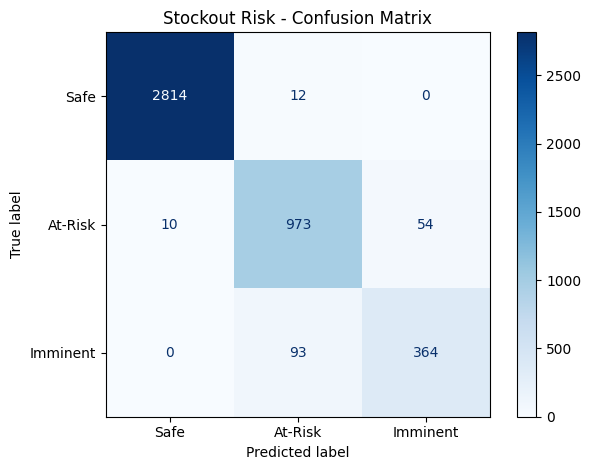

In [37]:
# ============================================================
# STEP 9: Model Evaluation
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predictions
y_pred = stockout_model.predict(X_test)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("=" * 60)
print("MODEL EVALUATION")
print("=" * 60)

print(f"\nAccuracy: {accuracy:.4f}")
print(f"Accuracy (%): {accuracy * 100:.2f}%")

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion matrix
labels = ["Safe", "At-Risk", "Imminent"]

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

print("\nConfusion Matrix:")
print(cm)

# Display confusion matrix
plt.figure(figsize=(7, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Stockout Risk - Confusion Matrix")
plt.tight_layout()
plt.show()

In [38]:
# ============================================================
# STEP 9B: Store Model Performance
# ============================================================

report = classification_report(
    y_test,
    y_pred,
    output_dict=True
)

performance_df = pd.DataFrame(report).transpose()

display(performance_df.round(3))

,precision,recall,f1-score,support
At-Risk,0.903,0.938,0.920,1037.000
Imminent,0.871,0.796,0.832,457.000
Safe,0.996,0.996,0.996,2826.000
accuracy,0.961,0.961,0.961,0.961
macro avg,0.923,0.910,0.916,4320.000
weighted avg,0.961,0.961,0.960,4320.000


In [39]:
# ============================================================
# STEP 10: Feature Importance
# ============================================================

# Get the trained Random Forest
rf = stockout_model.named_steps["classifier"]

# Get feature names after preprocessing
feature_names = (
    stockout_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

# Get importance values
importance_values = rf.feature_importances_

# Create feature-importance table
feature_importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importance_values
}).sort_values(
    by="importance",
    ascending=False
)

print("Top 20 Most Important Features:")
display(feature_importance_df.head(20))

Top 20 Most Important Features:


,feature,importance
7,num__days_of_cover,0.484611
0,num__opening_stock,0.110926
5,num__lead_time_days_actual,0.056903
6,num__sales_velocity_7d,0.055041
3,num__reorder_point,0.039240
2,num__units_sold,0.032694
1,num__units_demanded,0.032241
9,num__base_lead_time_days,0.026454
10,num__lead_time_variance_days,0.023742
4,num__lead_time_days_expected,0.023188


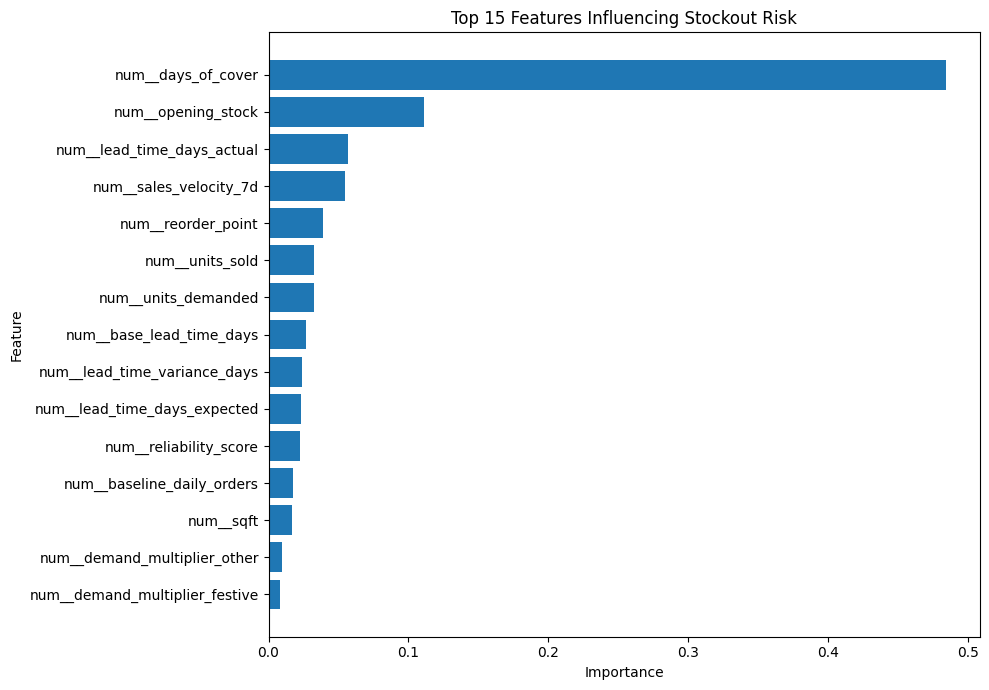

In [40]:
# ============================================================
# STEP 10B: Feature Importance Visualization
# ============================================================

top_features = feature_importance_df.head(15).sort_values(
    "importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["feature"],
    top_features["importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 Features Influencing Stockout Risk")

plt.tight_layout()
plt.show()

In [46]:
# ============================================================
# STEP 11: BUSINESS INSIGHTS
# ============================================================

print("=" * 70)
print("QUICKCART STOCKOUT RISK — BUSINESS INSIGHTS")
print("=" * 70)

# 1. Overall risk
risk_counts = df["stockout_risk"].value_counts()
risk_pct = df["stockout_risk"].value_counts(normalize=True) * 100

print("\n1. OVERALL STOCKOUT RISK")
print("-" * 40)

for risk in ["Safe", "At-Risk", "Imminent"]:
    print(
        f"{risk}: {risk_counts[risk]:,} records "
        f"({risk_pct[risk]:.2f}%)"
    )

# 2. Festival vs non-festival
print("\n2. FESTIVAL EFFECT")
print("-" * 40)

festival_risk = pd.crosstab(
    df["is_festival_week"],
    df["stockout_risk"],
    normalize="index"
) * 100

display(festival_risk.round(2))

# 3. Supplier reliability groups
print("\n3. SUPPLIER RELIABILITY")
print("-" * 40)

df["reliability_group"] = pd.cut(
    df["reliability_score"],
    bins=[-np.inf, 0.75, 0.85, np.inf],
    labels=["Low (<0.75)", "Mid (0.75–0.85)", "High (>=0.85)"]
)

reliability_risk = pd.crosstab(
    df["reliability_group"],
    df["stockout_risk"],
    normalize="index"
) * 100

display(reliability_risk.round(2))

# 4. Perishable vs non-perishable
print("\n4. PERISHABLE PRODUCTS")
print("-" * 40)

perishable_risk = pd.crosstab(
    df["is_perishable"],
    df["stockout_risk"],
    normalize="index"
) * 100

display(perishable_risk.round(2))

# 5. Top model features
print("\n5. TOP MODEL FEATURES")
print("-" * 40)

display(
    feature_importance_df.head(10)[
        ["feature", "importance"]
    ].round(4)
)

QUICKCART STOCKOUT RISK — BUSINESS INSIGHTS

1. OVERALL STOCKOUT RISK
----------------------------------------
Safe: 14,131 records (65.42%)
At-Risk: 5,186 records (24.01%)
Imminent: 2,283 records (10.57%)

2. FESTIVAL EFFECT
----------------------------------------


stockout_risk,At-Risk,Imminent,Safe
is_festival_week,,,
N,24.19,9.51,66.30
Y,21.80,23.31,54.89



3. SUPPLIER RELIABILITY
----------------------------------------


stockout_risk,At-Risk,Imminent,Safe
reliability_group,,,
Low (<0.75),21.63,13.07,65.30
Mid (0.75–0.85),17.57,3.26,79.17
High (>=0.85),34.88,3.82,61.30



4. PERISHABLE PRODUCTS
----------------------------------------


stockout_risk,At-Risk,Imminent,Safe
is_perishable,,,
N,24.64,9.30,66.06
Y,22.92,12.77,64.32



5. TOP MODEL FEATURES
----------------------------------------


,feature,importance
7,num__days_of_cover,0.4846
0,num__opening_stock,0.1109
5,num__lead_time_days_actual,0.0569
6,num__sales_velocity_7d,0.0550
3,num__reorder_point,0.0392
2,num__units_sold,0.0327
1,num__units_demanded,0.0322
9,num__base_lead_time_days,0.0265
10,num__lead_time_variance_days,0.0237
4,num__lead_time_days_expected,0.0232


In [47]:
# ============================================================
# STEP 12: FINAL CONCLUSIONS & RECOMMENDATIONS
# ============================================================

print("=" * 75)
print("QUICKCART STOCKOUT RISK — FINAL CONCLUSIONS")
print("=" * 75)

# Overall distribution
safe_pct = (df["stockout_risk"] == "Safe").mean() * 100
atrisk_pct = (df["stockout_risk"] == "At-Risk").mean() * 100
imminent_pct = (df["stockout_risk"] == "Imminent").mean() * 100

print("\n1. KEY FINDINGS")
print("-" * 50)

print(f"• Safe records:     {safe_pct:.2f}%")
print(f"• At-Risk records:  {atrisk_pct:.2f}%")
print(f"• Imminent records: {imminent_pct:.2f}%")

# Festival comparison
festival_imminent = (
    df[df["is_festival_week"] == 1]["stockout_risk"]
    .eq("Imminent").mean() * 100
)

nonfestival_imminent = (
    df[df["is_festival_week"] == 0]["stockout_risk"]
    .eq("Imminent").mean() * 100
)

print(
    f"\n• Imminent risk during festival period: "
    f"{festival_imminent:.2f}%"
)

print(
    f"• Imminent risk outside festival period: "
    f"{nonfestival_imminent:.2f}%"
)

# Reliability comparison
print("\n2. SUPPLIER RELIABILITY INSIGHT")
print("-" * 50)

for group in ["Low (<0.75)", "Mid (0.75–0.85)", "High (>=0.85)"]:
    subset = df[df["reliability_group"] == group]

    if len(subset) > 0:
        imminent = (
            subset["stockout_risk"]
            .eq("Imminent")
            .mean() * 100
        )

        print(
            f"• {group}: {imminent:.2f}% Imminent risk"
        )

# Perishable comparison
print("\n3. PRODUCT TYPE INSIGHT")
print("-" * 50)

for value in [0, 1]:
    subset = df[df["is_perishable"] == value]

    if len(subset) > 0:
        label = "Perishable" if value == 1 else "Non-perishable"

        imminent = (
            subset["stockout_risk"]
            .eq("Imminent")
            .mean() * 100
        )

        print(
            f"• {label}: {imminent:.2f}% Imminent risk"
        )

# Recommendations
print("\n4. BUSINESS RECOMMENDATIONS")
print("-" * 50)

print("""
1. Prioritize Imminent-risk SKU/store combinations
   for immediate replenishment and inventory review.

2. Increase inventory monitoring before and during
   festival demand periods.

3. Closely monitor suppliers with lower reliability
   scores and consider additional safety stock.

4. Monitor perishable products carefully because
   stock availability must be balanced against
   product shelf life.

5. Use the ML model as an early-warning system to
   identify high-risk inventory combinations before
   a stockout occurs.

6. Recalculate risk regularly as demand, inventory
   levels, supplier performance, and seasonal events
   change.
""")

print("=" * 75)
print("FINAL CONCLUSION")
print("=" * 75)

print("""
The QuickCart Stockout Risk project demonstrates how
historical inventory, demand, supplier, store, product,
and event information can be combined to identify
potential stockout risk.

The analysis shows that stockout risk is associated with
inventory conditions, demand patterns, supplier reliability,
product characteristics, and festival periods.

The resulting machine-learning workflow can support
proactive inventory management by helping QuickCart
identify potentially risky SKU/store combinations and
prioritize replenishment decisions.
""")

QUICKCART STOCKOUT RISK — FINAL CONCLUSIONS

1. KEY FINDINGS
--------------------------------------------------
• Safe records:     65.42%
• At-Risk records:  24.01%
• Imminent records: 10.57%

• Imminent risk during festival period: nan%
• Imminent risk outside festival period: nan%

2. SUPPLIER RELIABILITY INSIGHT
--------------------------------------------------
• Low (<0.75): 13.07% Imminent risk
• Mid (0.75–0.85): 3.26% Imminent risk
• High (>=0.85): 3.82% Imminent risk

3. PRODUCT TYPE INSIGHT
--------------------------------------------------

4. BUSINESS RECOMMENDATIONS
--------------------------------------------------

1. Prioritize Imminent-risk SKU/store combinations
   for immediate replenishment and inventory review.

2. Increase inventory monitoring before and during
   festival demand periods.

3. Closely monitor suppliers with lower reliability
   scores and consider additional safety stock.

4. Monitor perishable products carefully because
   stock availability must 